# <b>Task 3.2 - Robustness, Statistical Superiority, and Overfitting Control.</b>

**Goal:** prove that our best filters are better than random, stable across time,
and that results are not inflated by look-ahead or autocorrelation.

**Key insight driving the entire analysis:** per-trade PnL is heavily autocorrelated
(overlapping markout windows). All tests therefore run on daily Score aggregates (~180 days), where autocorrelation is weak and manageable.

**Ladder of methods (simple -> advanced):**
1. Walk-forward and rolling-window backtesting.
2. Purged + embargoed CV and CPCV.
3. Statistical tests (Diebold-Mariano HAC, permutation test).
4. Bootstrap comparison: IID vs Block vs Bayesian vs Bayesian-Block.

**Inputs:** `data/enriched/btc_sub10.parquet`.

## <b>Imports.</b>

In [1]:
import numpy as np
import polars as pl
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import utilities_score as us
import utilities_baselines as ub
import utilities_validation as uv

## <b>Load Data / Compute daily Score.</b>

In [2]:
# Path to data.
DATA_PATH = r"data/enriched/btc_sub10.parquet"

In [3]:
# Download data.
data = pl.read_parquet(DATA_PATH)

# Convert NaN -> Null in PnL columns for safe polars aggregation.
pnl_cols = [f"pnl_{t}s" for t in us.HORIZONS_S]

data = data.with_columns([
    pl.when(pl.col(c).is_nan()).then(None).otherwise(pl.col(c)).alias(c)
    for c in pnl_cols
])

n = data.shape[0]
print(f"Loaded: {n:,} trades")

Loaded: 80,403,526 trades


In [4]:
# define baselines to validate (from Phase 1).
BASELINES = {}

# random 30% - null hypothesis.
BASELINES["Random 30%"] = ub.random_filter(n, 0.3, seed=42)

# threshold baselines (same logic as Phase 1).
feature_configs = [
    ("vpin_5s",         "above", 0.70, "VPIN 5s (q=70%)"),
    ("dist_to_mid",     "above", 0.10, "Dist-to-mid above (q=10%)"),
    ("liq_binance_30s", "above", 0.10, "Liq Binance 30s (q=10%)"),
    ("liq_bybit_30s",   "above", 0.10, "Liq Bybit 30s (q=10%)"),
    ("obi",             "below", 0.90, "OBI (ask-heavy) (q=90%)")
]

for col_name, direction, quantile, label in feature_configs:
    values = ub.get_feature_array(data, col_name)
    valid  = values[~np.isnan(values)]
    thresh = float(np.quantile(valid, quantile))
    f_arr  = ub.threshold_filter(values, thresh, direction)
    BASELINES[label] = f_arr
    r = us.compute_score(data, f_arr, tau=30)
    print(f"{label:<30s}  Score_30={r.score:+.4f}  filter={r.filter_rate:.1%}")

print(f"\nTotal baselines: {len(BASELINES)}")

VPIN 5s (q=70%)                 Score_30=+0.0368  filter=30.0%
Dist-to-mid above (q=10%)       Score_30=+0.6468  filter=90.0%
Liq Binance 30s (q=10%)         Score_30=+0.5065  filter=90.0%
Liq Bybit 30s (q=10%)           Score_30=+0.4392  filter=90.0%
OBI (ask-heavy) (q=90%)         Score_30=+0.0589  filter=90.0%

Total baselines: 6


In [5]:
# compute daily Score arrays for each baseline (tau=30).
TAU = 30
daily_scores = {}

for label, f_arr in BASELINES.items():
    df_daily            = us.compute_daily_scores(data, f_arr, tau=TAU)
    daily_scores[label] = df_daily["score"].to_numpy().astype(np.float64)

n_days = len(daily_scores["Random 30%"])
print(f"Number of days: {n_days}")
print(f"Daily Score arrays computed for {len(daily_scores)} baselines")

# also compute daily PnL_all (no filter) for reference.
f_none          = ub.no_filter(n)
df_daily_none   = us.compute_daily_scores(data, f_none, tau=TAU)
daily_pnl_all   = df_daily_none["pnl_all"].to_numpy().astype(np.float64)


Number of days: 179
Daily Score arrays computed for 6 baselines


## <b>1. Autocorrelation of daily Scores.</b>

Before choosing bootstrap block length, we must check if daily Scores are autocorrelated.

If ACF(1) ~= 0, block bootstrap and IID give similar results.

If ACF(1) > 0, IID underestimates variance - block bootstrap is necessary.

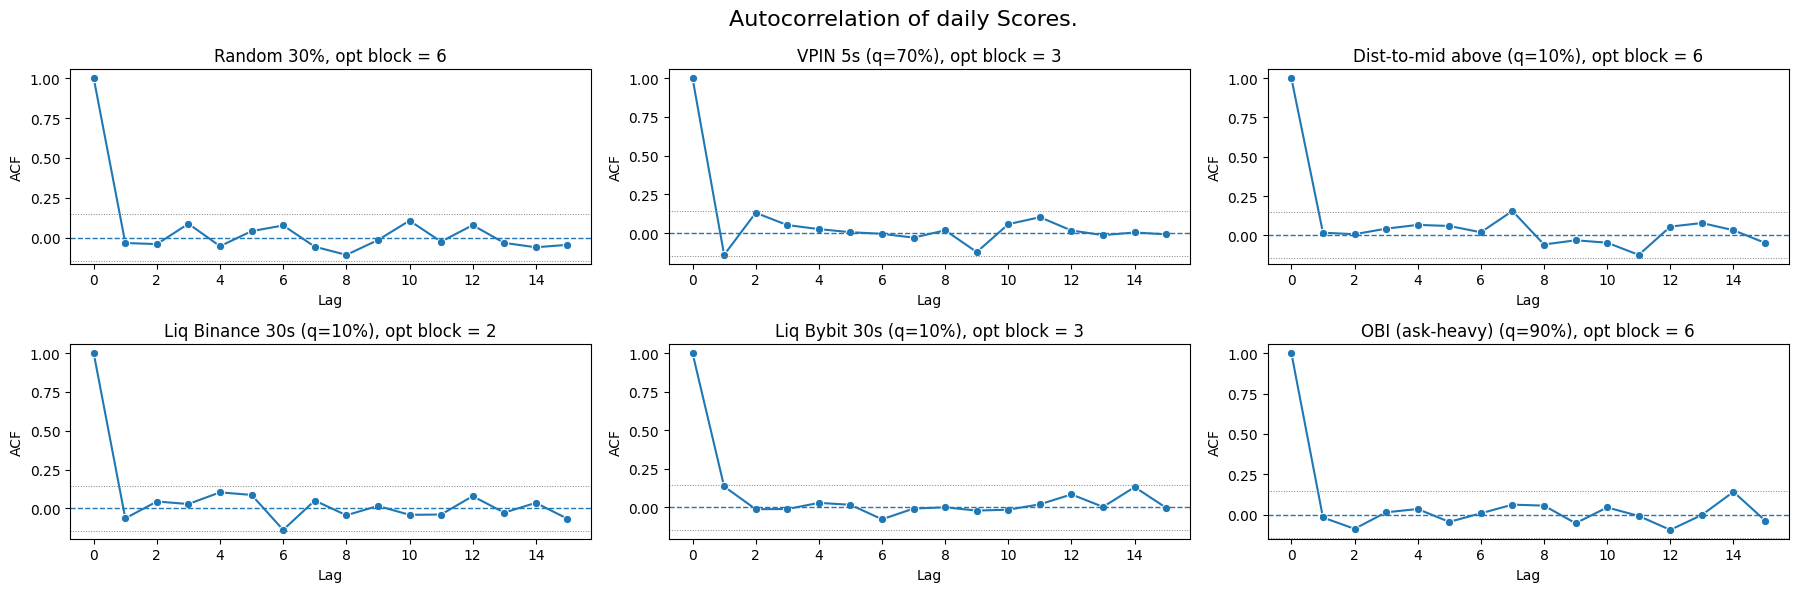

In [6]:
# ACF for filters and block length for bootstraps.
acfs = []
opts = []
labels = []

acf_random = uv.acf(daily_scores['Random 30%'], max_lag=15)
opt_random = uv.optimal_block_length(daily_scores['Random 30%'])
acfs.append(acf_random)
opts.append(opt_random)
labels.append('Random 30%')

for _, _, _, label in feature_configs:
    acf = uv.acf(daily_scores[label], max_lag=15)
    opt = uv.optimal_block_length(daily_scores[label])

    acfs.append(acf)
    opts.append(opt)
    labels.append(label)


# Plot ACF.
fig, axes = plt.subplots(2, 3, figsize=(18, 6))
axes = axes.ravel()

for i, (acf, opt, label) in enumerate(zip(acfs, opts, labels)):
    ax = axes[i]

    sns.lineplot(
        x   = np.arange(len(acf)),
        y   = acf,
        marker = "o",
        ax  = ax
    )

    bartlett = 1.96 / np.sqrt(n_days)
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.axhline(bartlett, linestyle=":", linewidth=0.7, color="gray")
    ax.axhline(-bartlett, linestyle=":", linewidth=0.7, color="gray")

    ax.set_title(f"{label}, opt block = {opt}")
    ax.set_xlabel("Lag")
    ax.set_ylabel("ACF")

# Remove extra plots.
for j in range(len(acfs), len(axes)):
    axes[j].axis("off")

fig.suptitle("Autocorrelation of daily Scores.", fontsize=16)
plt.tight_layout()
plt.show()

In [7]:
# check that we don't have significant autocorrelation.

acf_val = np.array(acfs)[:,1].max()

# Bartlett 95% band: ±1.96 / sqrt(T).
bartlett = 1.96 / np.sqrt(n_days)
print(f"Bartlett 95% band: ±{bartlett:.4f}")
print(f"ACF(1) {'>' if abs(acf_val) > bartlett else '<='} Bartlett band -> "
      f"{'significant' if abs(acf_val) > bartlett else 'not significant'} autocorrelation.")

Bartlett 95% band: ±0.1465
ACF(1) <= Bartlett band -> not significant autocorrelation.


## <b>2. Walk-forward backtesting.</b>

Split ~180 days into rolling windows: 30 days train / 15 days test.

On each fold, find optimal threshold on train, evaluate Score on test.

This removes look-ahead in threshold selection.

Walk-forward splits: 9 folds
  Fold 0: train days [0-29], test days [30-44]
  Fold 1: train days [15-44], test days [45-59]
  Fold 2: train days [30-59], test days [60-74]
  Fold 3: train days [45-74], test days [75-89]
  Fold 4: train days [60-89], test days [90-104]
  Fold 5: train days [75-104], test days [105-119]
  Fold 6: train days [90-119], test days [120-134]
  Fold 7: train days [105-134], test days [135-149]
  Fold 8: train days [120-149], test days [150-164]


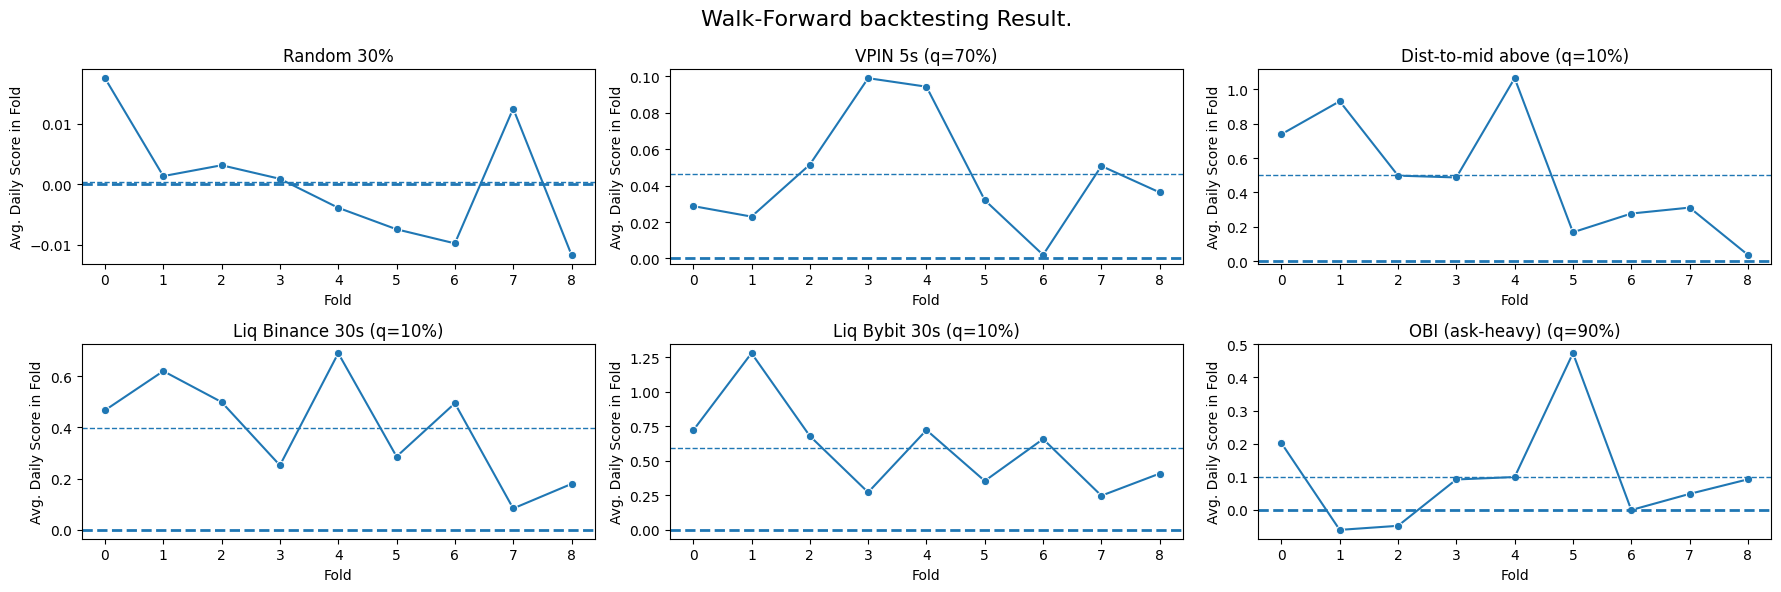

In [8]:
# walk-forward setup.
TRAIN_DAYS = 30
TEST_DAYS  = 15

# made wf split.
wf_splits = uv.walk_forward_splits(n_days, TRAIN_DAYS, TEST_DAYS)

# print split.
print(f"Walk-forward splits: {len(wf_splits)} folds")
for i, (tr, te) in enumerate(wf_splits):
    print(f"  Fold {i}: train days [{tr[0]}-{tr[-1]}], test days [{te[0]}-{te[-1]}]")


# Plot WF results.
fig, axes = plt.subplots(2, 3, figsize=(18, 6))
axes = axes.ravel()


for i, (label, daily_sc) in enumerate(daily_scores.items()):

    # claculate WF results for filter.
    fold_scores = []
    for tr_idx, te_idx in wf_splits:
        test_score = daily_sc[te_idx].mean()
        fold_scores.append(test_score)
    mean_sc = np.mean(fold_scores)

    # plot results.
    ax = axes[i]

    sns.lineplot(
        x   = np.arange(len(wf_splits)),
        y   = fold_scores,
        marker = "o",
        ax  = ax
    )

    ax.axhline(mean_sc, linestyle="--", linewidth=1)
    ax.axhline(0, linestyle="--", linewidth=2)

    ax.set_title(f"{label}")
    ax.set_xlabel("Fold")
    ax.set_ylabel("Avg. Daily Score in Fold")


fig.suptitle("Walk-Forward backtesting Result.", fontsize=16)
plt.tight_layout()
plt.show()

## <b>3. Rolling-window backtesting.</b>

Finer granularity: 14 days train / 7 days test, step 7 days.

More folds -> better stability estimate.

Rolling-window splits: 23 folds
  Fold 0: train days [0-13], test days [14-20]
  Fold 1: train days [7-20], test days [21-27]
  Fold 2: train days [14-27], test days [28-34]
  Fold 3: train days [21-34], test days [35-41]
  Fold 4: train days [28-41], test days [42-48]
  Fold 5: train days [35-48], test days [49-55]
  Fold 6: train days [42-55], test days [56-62]
  Fold 7: train days [49-62], test days [63-69]
  Fold 8: train days [56-69], test days [70-76]
  Fold 9: train days [63-76], test days [77-83]
  Fold 10: train days [70-83], test days [84-90]
  Fold 11: train days [77-90], test days [91-97]
  Fold 12: train days [84-97], test days [98-104]
  Fold 13: train days [91-104], test days [105-111]
  Fold 14: train days [98-111], test days [112-118]
  Fold 15: train days [105-118], test days [119-125]
  Fold 16: train days [112-125], test days [126-132]
  Fold 17: train days [119-132], test days [133-139]
  Fold 18: train days [126-139], test days [140-146]
  Fold 19: train days [133

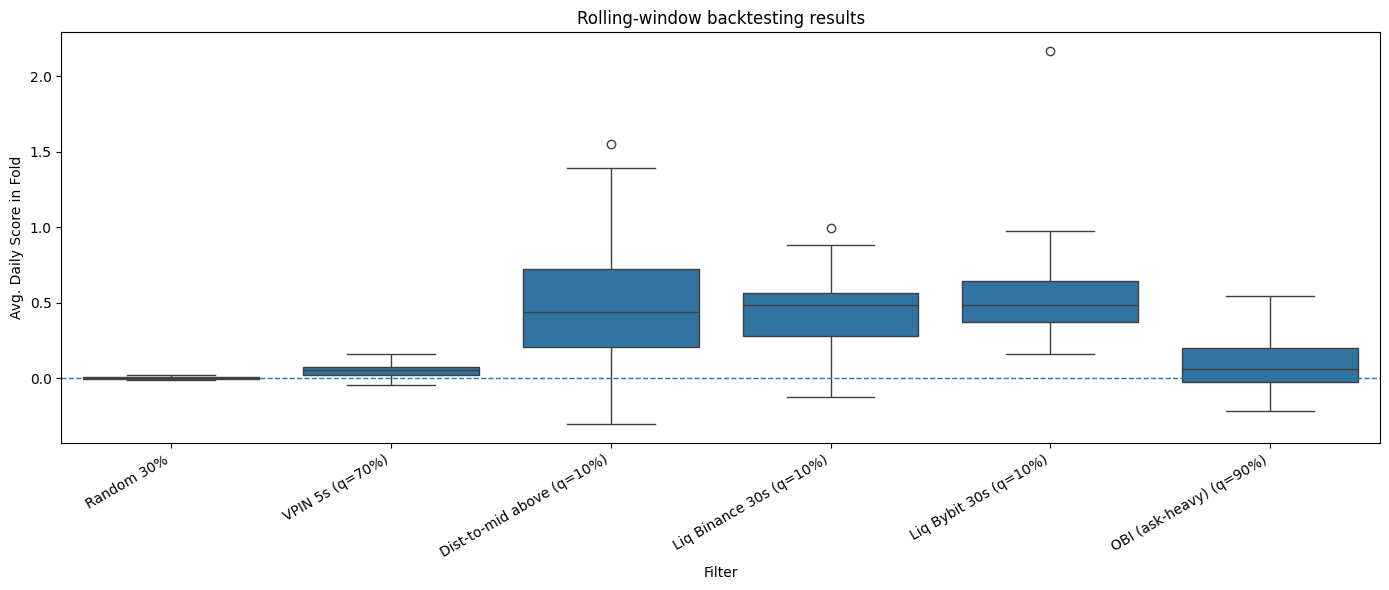

In [9]:
# RW Split.
rw_splits = uv.rolling_window_splits(n_days, train_size=14, test_size=7, step_size=7)

# print split.
print(f"Rolling-window splits: {len(rw_splits)} folds")
for i, (tr, te) in enumerate(rw_splits):
    print(f"  Fold {i}: train days [{tr[0]}-{tr[-1]}], test days [{te[0]}-{te[-1]}]")


# collect per-fold test Scores for each baseline.
rw_results = {}
for label, daily_sc in daily_scores.items():
    fold_scores = [daily_sc[te].mean() for _, te in rw_splits]
    rw_results[label] = fold_scores

# show statistics.
print(f"\n{'Filter':<30s} | {'Mean':>8} | {'Std':>8} | {'Min':>8} | {'Max':>8} | {'% > 0':>6}")
print("-" * 80)
for label, scores in rw_results.items():
    s = np.array(scores)
    pct_pos = 100 * np.mean(s > 0)
    print(f"{label:<30s} | {s.mean():>+8.4f} | {s.std():>8.4f} | {s.min():>+8.4f} | {s.max():>+8.4f} | {pct_pos:>5.1f}%")

# Convert rw_results to long format.
rw_plot_df = (
    pd.DataFrame(rw_results)
    .reset_index(names="fold")
    .melt(
        id_vars     = "fold",
        var_name    = "Filter",
        value_name  = "Avg. Daily Score in Fold"
    )
)

# Plot box-plot.
fig, ax = plt.subplots(figsize=(14, 6))

sns.boxplot(
    data    = rw_plot_df,
    x       = "Filter",
    y       = "Avg. Daily Score in Fold",
    ax      = ax
)


ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title("Rolling-window backtesting results")
ax.set_xlabel("Filter")
ax.set_ylabel("Avg. Daily Score in Fold")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### <b>Note on purge in walk-forward.</b>

Walk-forward and rolling window train exclusively on past data.

Filter thresholds (spread median, flow quantile) are computed from features that are backward-looking - markout is never used forthreshold estimation. 

The only theoretical leakage is the last ~300 s of train-period markout evaluation bleeding into the first test day - this affects < 0.3% of one day's trades and is negligible at daily Score granularity.

Purge is therefore **not required** in walk-forward 

## <b>4. Purged + embargoed CV.</b>

K=5 folds with 1-day purge and 1-day embargo.

Purge prevents markout leakage from train into test.

Embargo provides symmetric protection.


Purged CV: 5 folds
  Fold 0: train 143 days, test 35 days, train range [36-178], test range [0-34]
  Fold 1: train 142 days, test 35 days, train range [0-178], test range [35-69]
  Fold 2: train 142 days, test 35 days, train range [0-178], test range [70-104]
  Fold 3: train 142 days, test 35 days, train range [0-178], test range [105-139]
  Fold 4: train 139 days, test 39 days, train range [0-138], test range [140-178]


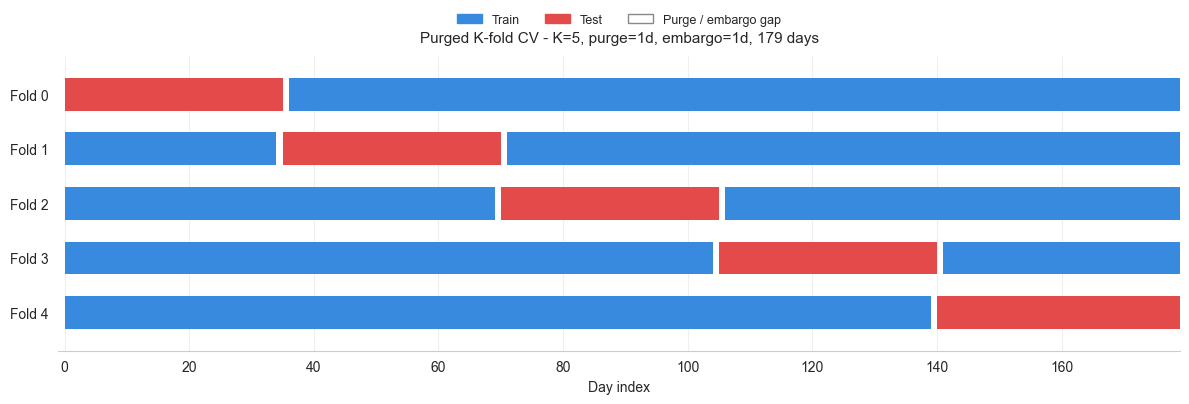

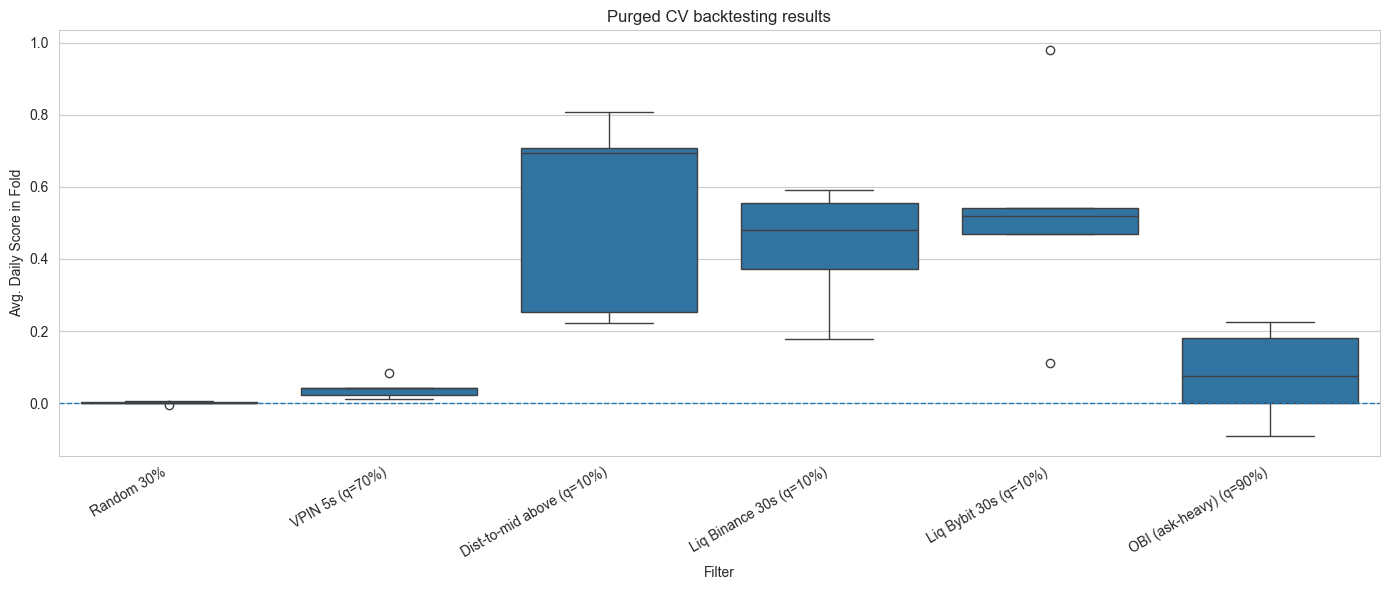

In [10]:
# calculate folds.
pcv_splits = uv.purged_kfold_splits(n_days, n_folds=5, purge_days=1, embargo_days=1)
print(f"Purged CV: {len(pcv_splits)} folds")
for i, (tr, te) in enumerate(pcv_splits):
    print(f"  Fold {i}: train {len(tr)} days, test {len(te)} days, "
          f"train range [{tr[0]}-{tr[-1]}], test range [{te[0]}-{te[-1]}]")


# plot folds.
def _contiguous_segments(idx):
    if len(idx) == 0:
        return []
    idx = np.asarray(idx)
    breaks = np.where(np.diff(idx) > 1)[0]
    starts = np.r_[idx[0], idx[breaks + 1]]
    ends = np.r_[idx[breaks], idx[-1]]
    return [(int(s), int(e - s + 1)) for s, e in zip(starts, ends)]

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(12, 4.2))

train_color = "#378ADD"
test_color = "#E24B4A"
bar_height = 0.6
n_folds = len(pcv_splits)

for i, (tr, te) in enumerate(pcv_splits):
    y = n_folds - 1 - i  # Fold 0 сверху
    ax.broken_barh(_contiguous_segments(tr), (y - bar_height / 2, bar_height),
                   facecolors=train_color, edgecolors="none")
    ax.broken_barh(_contiguous_segments(te), (y - bar_height / 2, bar_height),
                   facecolors=test_color, edgecolors="none")

ax.set_yticks(range(n_folds))
ax.set_yticklabels([f"Fold {n_folds - 1 - i}" for i in range(n_folds)])
ax.set_xlabel("Day index")
ax.set_xlim(-1, n_days)
ax.set_ylim(-0.7, n_folds - 0.3)
ax.set_title(f"Purged K-fold CV - K={n_folds}, purge=1d, embargo=1d, {n_days} days",
             fontsize=11, pad=10)

ax.legend(handles=[
    mpatches.Patch(color=train_color, label="Train"),
    mpatches.Patch(color=test_color, label="Test"),
    mpatches.Patch(facecolor="white", edgecolor="#888", label="Purge / embargo gap"),
], loc="upper center", bbox_to_anchor=(0.5, 1.18), ncol=3, frameon=False, fontsize=9)

ax.grid(axis="x", alpha=0.3)
ax.grid(axis="y", visible=False)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()


# Collect PCV results.
pcv_results = {}

for label, daily_sc in daily_scores.items():
    
    fold_scores = []

    for _, te in pcv_splits:
        test_score = daily_sc[te].mean()
        fold_scores.append(test_score)

    pcv_results[label] = fold_scores

# Convert to long format.
pcv_plot_df = (
    pd.DataFrame(pcv_results)
    .reset_index(names="fold")
    .melt(
        id_vars     = "fold",
        var_name    = "Filter",
        value_name  = "Avg. Daily Score in Fold"
    )
)

# Plot box-plot.
fig, ax = plt.subplots(figsize=(14, 6))

sns.boxplot(
    data=pcv_plot_df,
    x   = "Filter",
    y   = "Avg. Daily Score in Fold",
    ax  = ax
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title("Purged CV backtesting results")
ax.set_xlabel("Filter")
ax.set_ylabel("Avg. Daily Score in Fold")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## <b>5. Combinatorial Purged CV (CPCV).</b>

K=6 groups, test_size=1 -> C(6,2) = 15 combinations.

Gives a distribution of out-of-sample Scores (not just one number).

CPCV combinations: 15


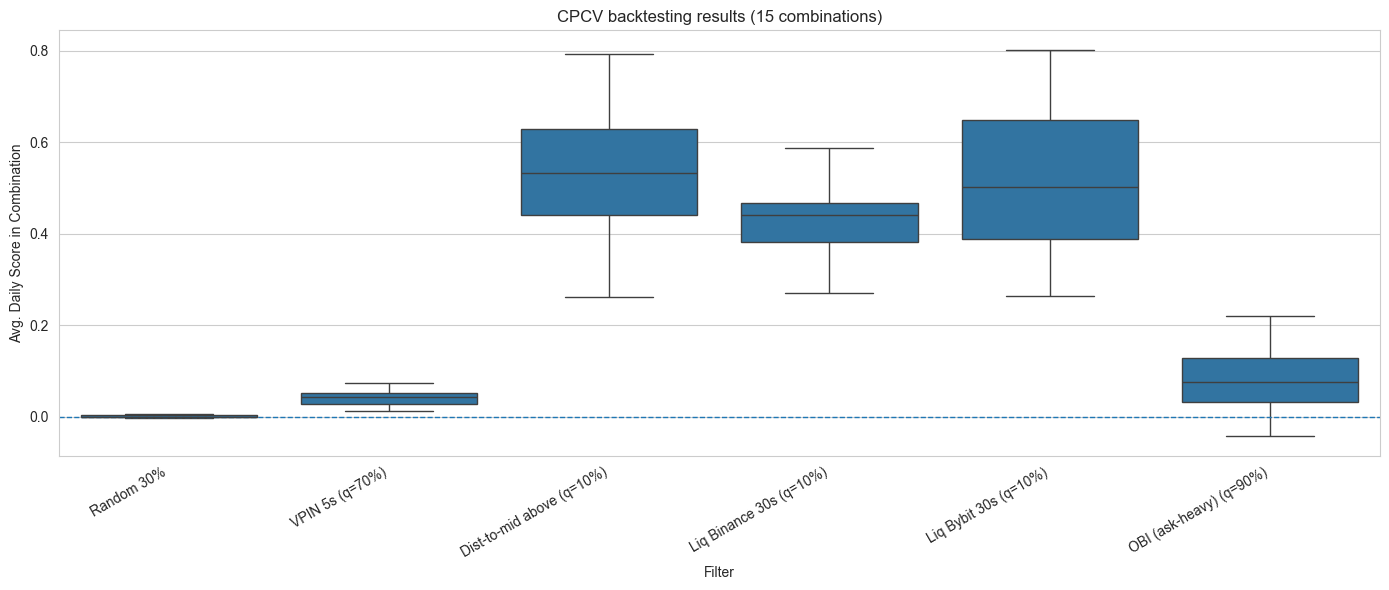

In [11]:
# cpcv split.
cpcv_splits = uv.cpcv_splits(n_days, n_groups=6, n_test_groups=2, purge_days=1, embargo_days=1)
print(f"CPCV combinations: {len(cpcv_splits)}")

# собрать результаты в long-format.
cpcv_results = {}
for label, daily_sc in daily_scores.items():
    cpcv_results[label] = [daily_sc[te].mean() for _, te in cpcv_splits]

cpcv_plot_df = (
    pd.DataFrame(cpcv_results)
    .reset_index(names="combination")
    .melt(
        id_vars    = "combination",
        var_name   = "Filter",
        value_name = "Avg. Daily Score in Combination"
    )
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(
    data = cpcv_plot_df,
    x    = "Filter",
    y    = "Avg. Daily Score in Combination",
    ax   = ax
)
ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title(f"CPCV backtesting results ({len(cpcv_splits)} combinations)")
ax.set_xlabel("Filter")
ax.set_ylabel("Avg. Daily Score in Combination")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## <b>6. Diebold-Mariano test (HAC).</b>

H0: Score(filter) - Score(random) = 0.

Uses Newey-West HAC variance to account for any residual autocorrelation.

In [12]:
d_random = daily_scores["Random 30%"]

print(f"{'Filter':<30s} | {'DM stat':>8} | {'p-value':>8} | {'Reject H0':>10} | {'CI 95%':>20}")
print("-" * 90)

dm_results = {}
for label, daily_sc in daily_scores.items():

    if label == "Random 30%": continue

    d       = daily_sc - d_random
    result  = uv.diebold_mariano_test(d)
    dm_results[label] = result

    ci_str = f"[{result.ci_low:+.4f}, {result.ci_high:+.4f}]" if result.ci_low is not None else ""
    reject_str = "YES" if result.reject_h0 else "no"
    print(f"{label:<30s} | {result.statistic:>+8.4f} | {result.p_value:>8.4f} | {reject_str:>10} | {ci_str:>20}")

Filter                         |  DM stat |  p-value |  Reject H0 |               CI 95%
------------------------------------------------------------------------------------------
VPIN 5s (q=70%)                |  +3.9765 |   0.0000 |        YES |   [+0.0201, +0.0593]
Dist-to-mid above (q=10%)      |  +6.2460 |   0.0000 |        YES |   [+0.3631, +0.6952]
Liq Binance 30s (q=10%)        |  +7.8964 |   0.0000 |        YES |   [+0.3221, +0.5349]
Liq Bybit 30s (q=10%)          |  +5.0230 |   0.0000 |        YES |   [+0.3137, +0.7151]
OBI (ask-heavy) (q=90%)        |  +1.6527 |   0.0492 |        YES |   [-0.0137, +0.1610]


## <b>7. Paired permutation test.</b>

H0: Score(filter) - Score(random) = 0.

Non-parametric alternative to DM. 

Randomly flips signs of daily differences.

No distributional assumptions.

In [13]:
print(f"{'Filter':<30s} | {'Obs mean':>10} | {'p-value':>8} | {'Reject H0':>10}")
print("-" * 75)

perm_results = {}
for label, daily_sc in daily_scores.items():
    if label == "Random 30%": continue

    d       = daily_sc - d_random
    result  = uv.paired_permutation_test(d, n_perms=10_000)
    perm_results[label] = result

    reject_str = "YES" if result.reject_h0 else "no"
    print(f"{label:<30s} | {result.statistic:>+10.6f} | {result.p_value:>8.4f} | {reject_str:>10}")

Filter                         |   Obs mean |  p-value |  Reject H0
---------------------------------------------------------------------------
VPIN 5s (q=70%)                |  +0.039709 |   0.0000 |        YES
Dist-to-mid above (q=10%)      |  +0.529146 |   0.0000 |        YES
Liq Binance 30s (q=10%)        |  +0.428508 |   0.0000 |        YES
Liq Bybit 30s (q=10%)          |  +0.514385 |   0.0000 |        YES
OBI (ask-heavy) (q=90%)        |  +0.073669 |   0.0585 |         no


## <b>8. Bootstrap: IID vs Block vs Bayesian vs Bayesian-Block vs ... .</b>

Central demonstration: IID bootstrap **underestimates** CI width because it ignores
temporal dependence. 

Block and Bayesian-block methods give wider, more honest CIs.

We apply all 6 methods to the daily Score of the best filter.

Compare CI widths. The ratio Block/IID shows how much IID underestimates uncertainty.
From the time-series bootstrap theory (and our reference notebook), we expect ratio > 1.

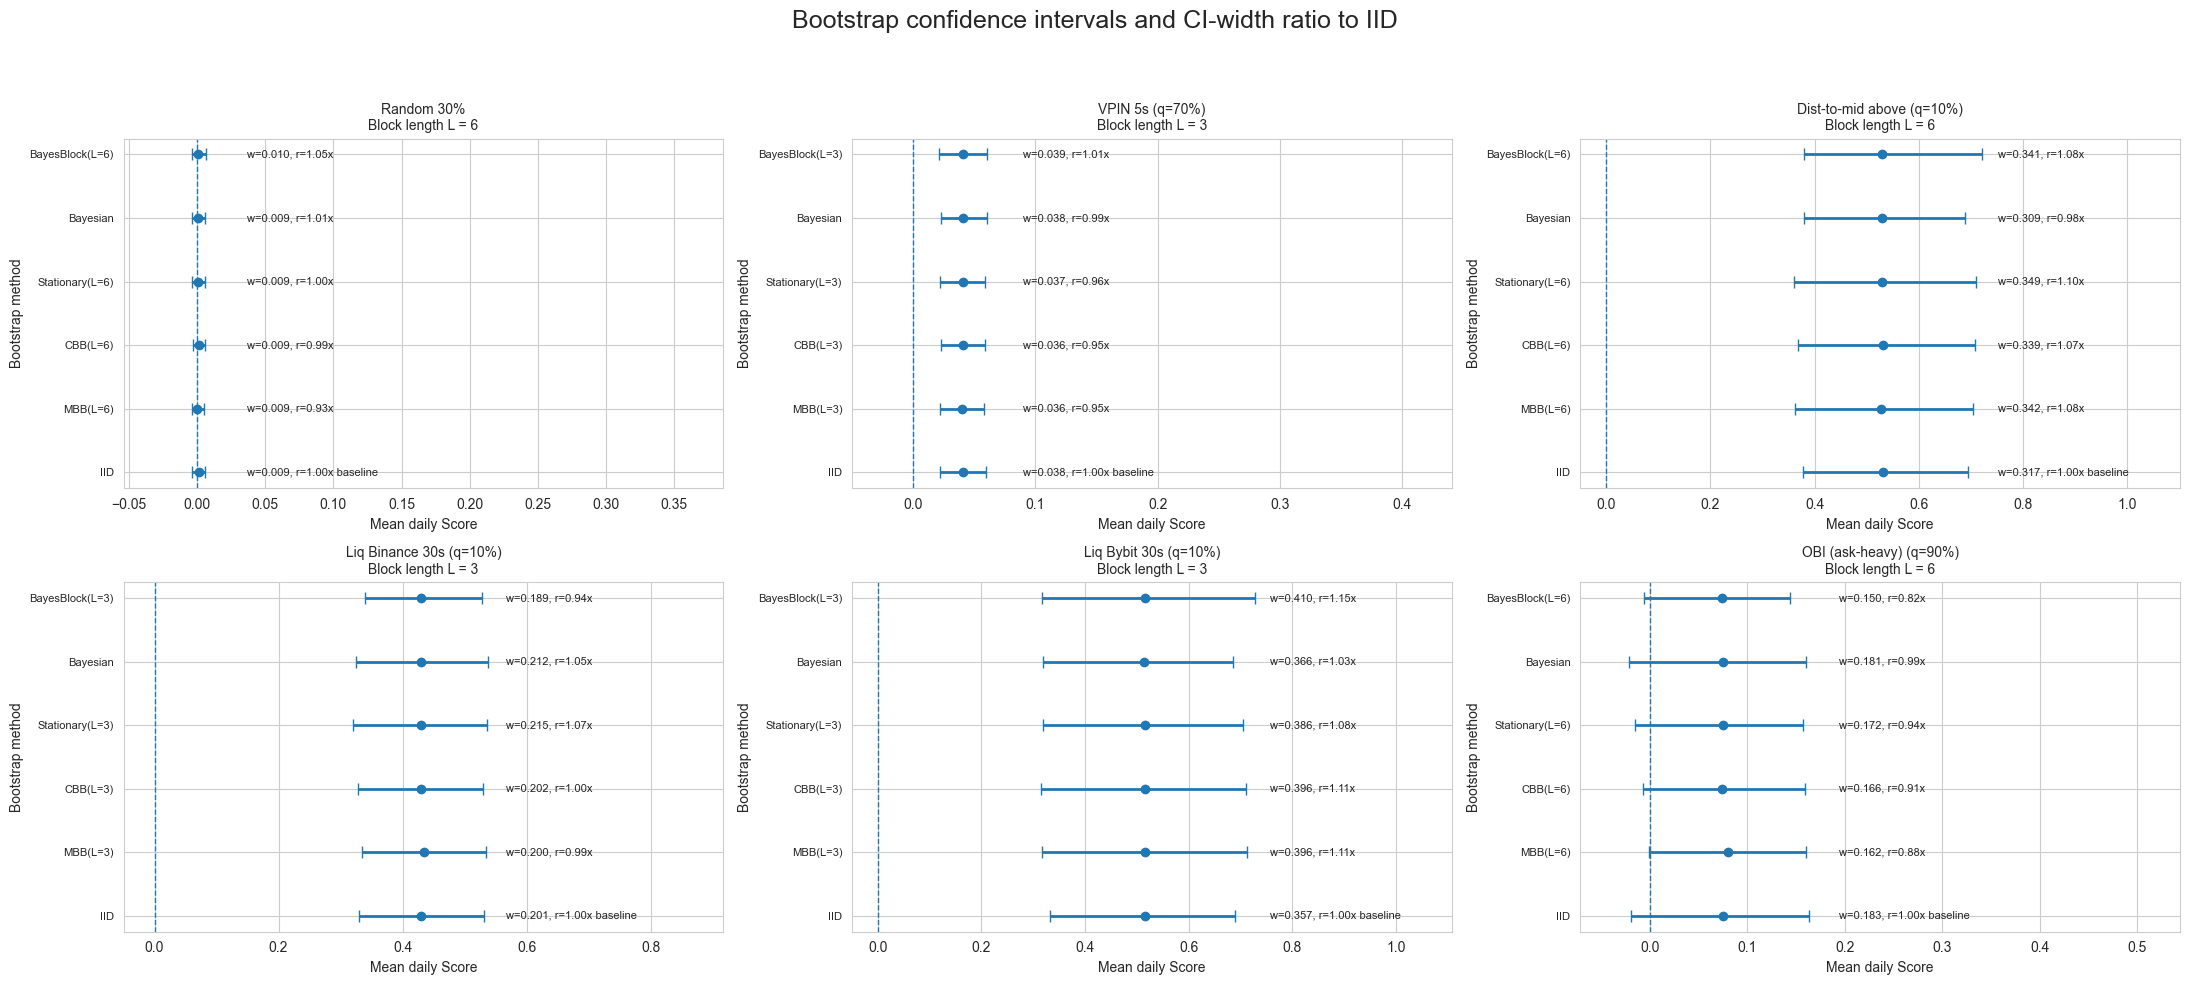

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(22, 10))
axes = axes.ravel()

for plot_idx, (label, daily_sc) in enumerate(daily_scores.items()):

    ax = axes[plot_idx]

    # Optimal block length.
    L = max(uv.optimal_block_length(daily_sc), 3)

    # Bootstrap results.
    boot_results = [
        uv.iid_bootstrap(daily_sc),
        uv.moving_block_bootstrap(daily_sc, block_len=L),
        uv.circular_block_bootstrap(daily_sc, block_len=L),
        uv.stationary_bootstrap(daily_sc, mean_block_len=L),
        uv.bayesian_bootstrap(daily_sc),
        uv.bayesian_block_bootstrap(daily_sc, block_len=L)
    ]

    df_boot = pl.DataFrame(uv.compare_bootstraps(boot_results))

    # Convert to pandas for plotting.
    df_plot = df_boot.to_pandas()

    # Make sure numeric columns are numeric.
    for col in ["mean", "CI_low", "CI_high", "CI_width", "std"]:
        df_plot[col] = pd.to_numeric(df_plot[col])

    # Ratio to IID.
    iid_width = df_plot.loc[df_plot["method"] == "IID", "CI_width"].iloc[0]
    df_plot["ratio_to_iid"] = df_plot["CI_width"] / iid_width

    # Asymmetric CI errors.
    xerr_low = df_plot["mean"] - df_plot["CI_low"]
    xerr_high = df_plot["CI_high"] - df_plot["mean"]

    y_pos = np.arange(len(df_plot))

    # Forest plot.
    ax.errorbar(
        x=df_plot["mean"],
        y=y_pos,
        xerr=[xerr_low, xerr_high],
        fmt="o",
        capsize=4,
        linewidth=2
    )

    ax.axvline(0, linestyle="--", linewidth=1)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(df_plot["method"], fontsize=8)

    ax.set_title(f"{label}\nBlock length L = {L}", fontsize=10)
    ax.set_xlabel("Mean daily Score")
    ax.set_ylabel("Bootstrap method")

    # Text labels: CI width and ratio to IID.
    x_text = df_plot["CI_high"].max() + 0.03

    for y, row in zip(y_pos, df_plot.itertuples()):
        marker = "baseline" if row.method == "IID" else ""

        ax.text(
            x_text,
            y,
            f"w={row.CI_width:.3f}, r={row.ratio_to_iid:.2f}x {marker}",
            va="center",
            fontsize=8
        )

    # Extend x-axis to make room for text.
    ax.set_xlim(
        left=min(0, df_plot["CI_low"].min()) - 0.05,
        right=x_text + 0.35
    )

# Hide unused axes if filters < 6.
for j in range(len(daily_scores), len(axes)):
    axes[j].axis("off")

fig.suptitle(
    "Bootstrap confidence intervals and CI-width ratio to IID",
    fontsize=18
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

The Block/IID CI-width ratio indicates whether accounting for temporal dependence increases the estimated uncertainty relative to IID bootstrap. 

When daily scores exhibit positive serial correlation, block-based methods are expected to produce wider confidence intervals. This pattern is observed for filters such as Dist-to-mid and Liq Bybit. 

However, for filters with very weak, or negative autocorrelation, the ratio can be close to or below one, so IID bootstrap does not necessarily underestimate variance for every daily-score series.

This result is also explained by the correct day-level data splitting: since observations were aggregated and separated by days, most daily-score series have weak autocorrelation, so block bootstrap does not necessarily produce wider confidence intervals than IID bootstrap.